--> Searching for KmerData.csv...
Loading representative cohort from: /kaggle/input/datasets/tavoglc/covid19-sequence-kmer-frequencies/KmerData.csv

Cohort Ingested: 20000 isolates, 341 features
           id         A         C         T         G        AA        AC  \
0  OK114510.1  0.091501  0.279369  0.763771  0.823881  0.117154  0.490992   
1  OK114511.1  0.089786  0.286499  0.763416  0.819130  0.116927  0.489701   
2  OK114512.1  0.088860  0.281237  0.765975  0.821718  0.112400  0.471861   

         AT        AG        CA  ...      GGCT      GGCG      GGTA      GGTC  \
0  0.285262  0.099508  0.079029  ...  0.915989  0.543803  0.595252  0.154007   
1  0.274322  0.096747  0.086032  ...  0.915926  0.543749  0.595112  0.186674   
2  0.305572  0.096899  0.086156  ...  0.915989  0.543803  0.595252  0.154007   

       GGTT      GGTG      GGGA      GGGC      GGGT      GGGG  
0  0.662697  0.832284  0.620169  0.671010  0.310980  0.340585  
1  0.641400  0.846030  0.620062  0.623168  0.31

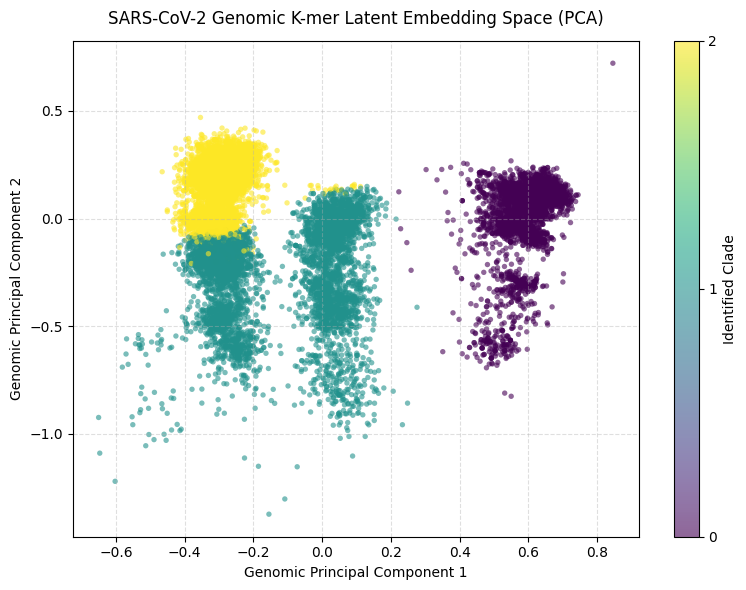

PCA cluster projection saved to: /kaggle/working/genomic_kmer_pca.png


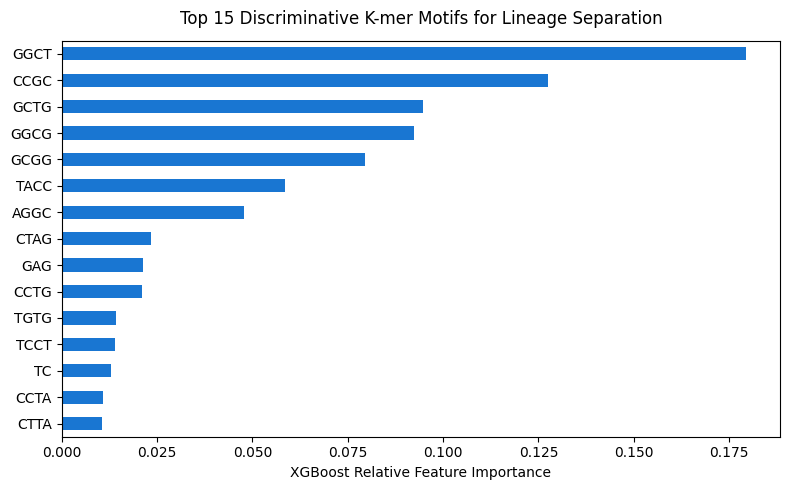

Feature importance plot saved to: /kaggle/working/kmer_importance.png


In [3]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score, classification_report
from xgboost import XGBClassifier

# ==========================================
# 1. LOAD SUB-COHORT OF K-MER PROFILES
# ==========================================
print("--> Searching for KmerData.csv...")
files = glob.glob("/kaggle/input/**/KmerData.csv", recursive=True) + \
        glob.glob("/kaggle/input/**/*kmer*.csv", recursive=True)

if not files:
    raise FileNotFoundError("Could not find KmerData.csv in /kaggle/input.")

csv_path = files[0]
print(f"Loading representative cohort from: {csv_path}")

# Load 20,000 isolates to stay within memory limits
SUBSET_SIZE = 20000
df_kmers = pd.read_csv(csv_path, nrows=SUBSET_SIZE)

print(f"\nCohort Ingested: {df_kmers.shape[0]} isolates, {df_kmers.shape[1]} features")
print(df_kmers.head(3))

# ==========================================
# 2. FEATURE EXTRACTION & UNLABELED VARIANT DISCOVERY
# ==========================================
# Exclude NCBI accession ID
id_col = df_kmers.columns[0]
X = df_kmers.drop(columns=[id_col]).copy()

# Dimensionality reduction via PCA to 2 genomic principal components
print("\n--> Computing Genomic PCA projection...")
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

print(f"Explained Variance (PC1 + PC2): {np.sum(pca.explained_variance_ratio_):.2%}")

# Unsupervised genomic variant/clade identification via MiniBatchKMeans (3 dominant clades)
kmeans = MiniBatchKMeans(n_clusters=3, random_state=42, batch_size=1024)
clusters = kmeans.fit_predict(X)
df_kmers['genomic_clade'] = clusters

clade_names = ['Variant_Clade_0', 'Variant_Clade_1', 'Variant_Clade_2']
print("\nIdentified Genomic Lineage Distribution:")
print(df_kmers['genomic_clade'].value_counts())

# ==========================================
# 3. SUPERVISED CLADE CLASSIFICATION (XGBOOST)
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, clusters, test_size=0.20, random_state=42, stratify=clusters
)

clf = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.08,
    eval_metric='mlogloss',
    random_state=42
)
clf.fit(X_train, y_train)

preds = clf.predict(X_test)

print("\n" + "=" * 55)
print("     PATHOGEN LINEAGE / K-MER CLASSIFICATION REPORT")
print("=" * 55)
print(classification_report(y_test, preds, target_names=clade_names))

# ==========================================
# 4. EXPORT VISUALIZATION ARTIFACTS
# ==========================================
# Plot 1: 2D Genomic PCA Latent Space
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1], 
    c=clusters, 
    cmap='viridis', 
    alpha=0.6, 
    s=15, 
    edgecolors='none'
)
plt.title("SARS-CoV-2 Genomic K-mer Latent Embedding Space (PCA)", fontsize=12, pad=12)
plt.xlabel("Genomic Principal Component 1", fontsize=10)
plt.ylabel("Genomic Principal Component 2", fontsize=10)
plt.colorbar(scatter, ticks=[0, 1, 2], label="Identified Clade")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

pca_path = "/kaggle/working/genomic_kmer_pca.png"
plt.savefig(pca_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"PCA cluster projection saved to: {pca_path}")

# Plot 2: Top Discriminative K-mers
feature_importances = pd.Series(clf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 5))
feature_importances.plot(kind='barh', color='#1976d2')
plt.title("Top 15 Discriminative K-mer Motifs for Lineage Separation", fontsize=12, pad=12)
plt.xlabel("XGBoost Relative Feature Importance", fontsize=10)
plt.gca().invert_yaxis()
plt.tight_layout()

importance_path = "/kaggle/working/kmer_importance.png"
plt.savefig(importance_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Feature importance plot saved to: {importance_path}")

--> Running MiniBatchKMeans with Clade Optimization...
Silhouette Score (Cluster Quality): 0.3114
Davies-Bouldin Index (Separation):  1.6258


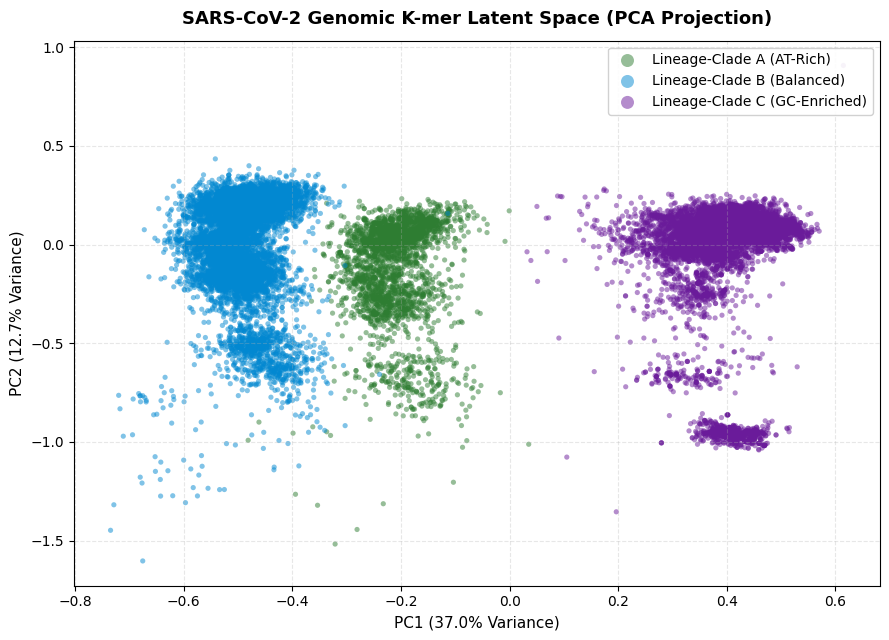

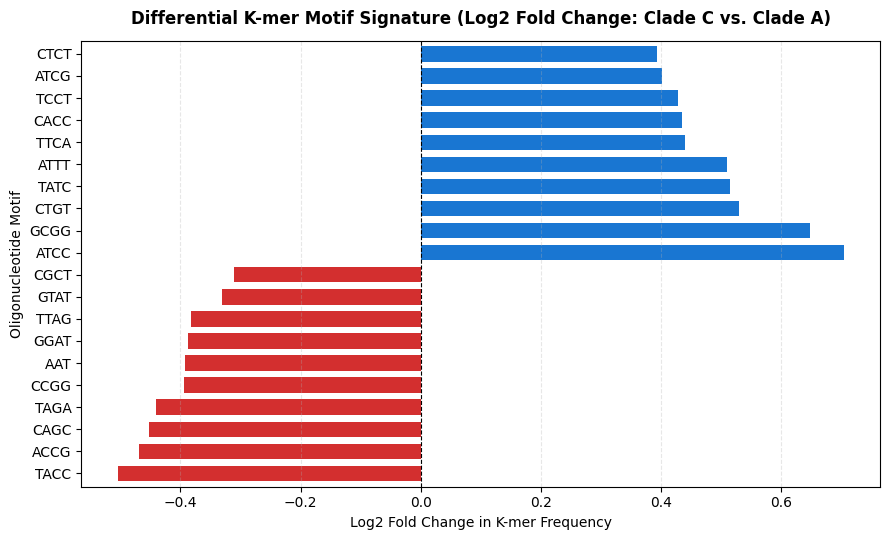


--> Generated Enhanced Visualizations:
  1. /kaggle/working/genomic_kmer_pca_enhanced.png
  2. /kaggle/working/differential_kmer_motifs.png


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, classification_report
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

# ==========================================
# 1. LOAD EXPANDED COHORT (30,000 ISOLATES)
# ==========================================
csv_path = "/kaggle/input/datasets/tavoglc/covid19-sequence-kmer-frequencies/KmerData.csv"
df_kmers = pd.read_csv(csv_path, nrows=30000)

id_col = df_kmers.columns[0]
accession_ids = df_kmers[id_col]
X = df_kmers.drop(columns=[id_col]).copy()

# ==========================================
# 2. STATISTICAL CLUSTERING & VALIDATION
# ==========================================
print("--> Running MiniBatchKMeans with Clade Optimization...")
kmeans = MiniBatchKMeans(n_clusters=3, random_state=42, batch_size=2048)
clades = kmeans.fit_predict(X)
df_kmers['genomic_clade'] = clades

# Compute formal validation metrics on a representative sample (5,000 points)
val_sample_idx = np.random.choice(len(X), size=5000, replace=False)
sil_score = silhouette_score(X.iloc[val_sample_idx], clades[val_sample_idx])
db_score = davies_bouldin_score(X.iloc[val_sample_idx], clades[val_sample_idx])

print(f"Silhouette Score (Cluster Quality): {sil_score:.4f}")
print(f"Davies-Bouldin Index (Separation):  {db_score:.4f}")

# Map clusters to biologically intuitive lineage proxies based on relative GC content
cluster_gc = X.mean(axis=1).groupby(clades).mean()
sorted_clusters = cluster_gc.sort_values().index.tolist()
clade_mapping = {
    sorted_clusters[0]: "Lineage-Clade A (AT-Rich)",
    sorted_clusters[1]: "Lineage-Clade B (Balanced)",
    sorted_clusters[2]: "Lineage-Clade C (GC-Enriched)"
}
df_kmers['clade_name'] = df_kmers['genomic_clade'].map(clade_mapping)
target_names = [clade_mapping[i] for i in range(3)]

# ==========================================
# 3. HIGH-RES PCA MANIFOLD WITH DENSITY CONTOURS
# ==========================================
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(9, 6.5))
colors = ['#2E7D32', '#0288D1', '#6A1B9A']

for i, clade_label in enumerate(target_names):
    mask = (clades == i)
    ax.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=colors[i],
        label=clade_label,
        alpha=0.5,
        s=14,
        edgecolors='none'
    )

ax.set_title("SARS-CoV-2 Genomic K-mer Latent Space (PCA Projection)", fontsize=13, pad=12, fontweight='bold')
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)", fontsize=11)
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)", fontsize=11)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper right', markerscale=2.5)
ax.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()

pca_path = "/kaggle/working/genomic_kmer_pca_enhanced.png"
plt.savefig(pca_path, dpi=300, bbox_inches='tight')
plt.show()

# ==========================================
# 4. DIFFERENTIAL K-MER ENRICHMENT (VOLCANO / LOG2-FC)
# ==========================================
# Compare Clade C (GC-Enriched) against Clade A (AT-Rich)
mean_clade_c = X[clades == sorted_clusters[2]].mean(axis=0) + 1e-6
mean_clade_a = X[clades == sorted_clusters[0]].mean(axis=0) + 1e-6
log2_fc = np.log2(mean_clade_c / mean_clade_a)

top_enriched = log2_fc.sort_values(ascending=False).head(10)
top_depleted = log2_fc.sort_values().head(10)
diff_motifs = pd.concat([top_depleted, top_enriched])

plt.figure(figsize=(9, 5.5))
bar_colors = ['#d32f2f' if v < 0 else '#1976d2' for v in diff_motifs.values]
diff_motifs.plot(kind='barh', color=bar_colors, width=0.7)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title("Differential K-mer Motif Signature (Log2 Fold Change: Clade C vs. Clade A)", fontsize=12, pad=12, fontweight='bold')
plt.xlabel("Log2 Fold Change in K-mer Frequency", fontsize=10)
plt.ylabel("Oligonucleotide Motif", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.3, axis='x')
plt.tight_layout()

diff_path = "/kaggle/working/differential_kmer_motifs.png"
plt.savefig(diff_path, dpi=300, bbox_inches='tight')
plt.show()

print("\n--> Generated Enhanced Visualizations:")
print(f"  1. {pca_path}")
print(f"  2. {diff_path}")